#  Building Good Training Datasets – Data Preprocessing

In [3]:
import pandas as pd 
from io import StringIO 


csv_data = \
  '''A,B,C,D
  1.0,2.0,3.0,4.0
  5.0,6.0,,8.0
  10.0,11.0,12.0,'''

df = pd.read_csv(StringIO(csv_data))
df.head()

,A,B,C,D
0,1.0,2.0,3.0,4.0
1,5.0,6.0,NaN,8.0
2,10.0,11.0,12.0,NaN


In [4]:
df.isnull().sum()

A    0
B    0
C    1
D    1
dtype: int64

In [5]:
df.values

array([[ 1.,  2.,  3.,  4.],
       [ 5.,  6., nan,  8.],
       [10., 11., 12., nan]])

### Eliminating training examples or features with missing values


In [6]:
df.dropna(axis = 0) # axis = 0 drop rows and axis = 1 drop columns 

,A,B,C,D
0,1.0,2.0,3.0,4.0


In [7]:
df.dropna(how = "all") #Only drops rows where all the values are Null

,A,B,C,D
0,1.0,2.0,3.0,4.0
1,5.0,6.0,NaN,8.0
2,10.0,11.0,12.0,NaN


In [8]:
df.dropna(thresh = 4) #drops if have fewer than 4 values 

,A,B,C,D
0,1.0,2.0,3.0,4.0


In [10]:
df.dropna(subset = ["C"]) # only drops when NA appears in the C column 

,A,B,C,D
0,1.0,2.0,3.0,4.0
2,10.0,11.0,12.0,NaN


# Imputing missing values 

- Often, the removal of training examples or dropping of entire feature columns is simply not feasible


In [11]:
 from sklearn.impute import SimpleImputer
 import numpy as np
 imr = SimpleImputer(missing_values=np.nan, strategy='mean')
 imr = imr.fit(df.values)
 imputed_data = imr.transform(df.values)
 imputed_data

array([[ 1. ,  2. ,  3. ,  4. ],
       [ 5. ,  6. ,  7.5,  8. ],
       [10. , 11. , 12. ,  6. ]])

In [13]:
df.fillna(df.mean())

,A,B,C,D
0,1.0,2.0,3.0,4.0
1,5.0,6.0,7.5,8.0
2,10.0,11.0,12.0,6.0


##  Understanding the scikit-learn estimator API

- The two essential methods of those estimators are 
    fit and transform. The fit method is used to learn the parameters from the training data, and the 
    transform method uses those parameters to transform the data. Any data array that is to be trans
    formed needs to have the same number of features as the data array that was used to fit the model.


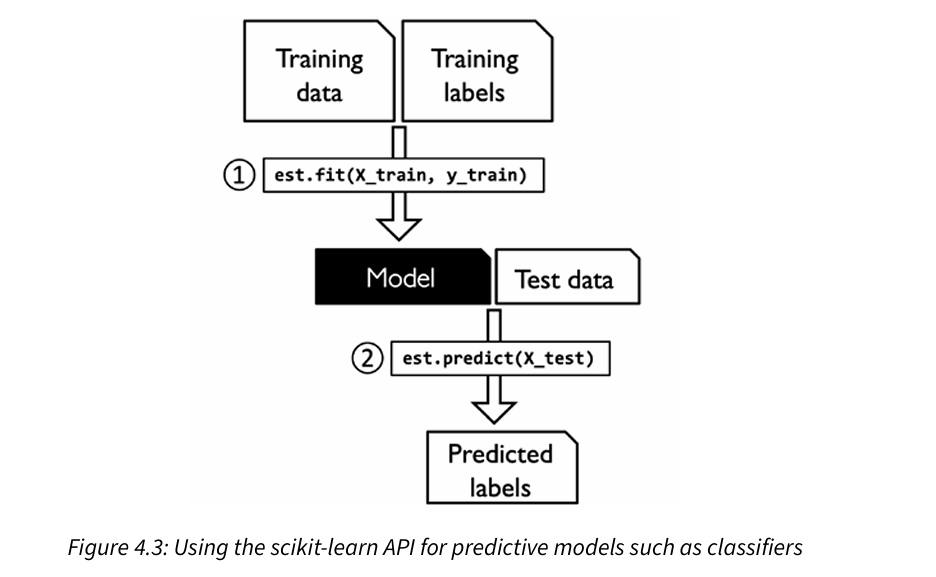

#  Handling categorical data

-  ordinal and nominal features.

- 

In [42]:
df = pd.DataFrame([
            ['green', 'M', 10.1, 'class2'],
            ['red', 'L', 13.5, 'class1'],
            ['blue', 'XL', 15.3, 'class2']])
df.columns = ['color', 'size', 'price', 'classlabel']

df

,color,size,price,classlabel
0,green,M,10.1,class2
1,red,L,13.5,class1
2,blue,XL,15.3,class2


In [43]:
size_mapping = {'XL': 3, 'L': 2, 'M': 1}

In [44]:
df['size'] = df['size'].map(size_mapping)
df

,color,size,price,classlabel
0,green,1,10.1,class2
1,red,2,13.5,class1
2,blue,3,15.3,class2


In [32]:
inv_size_mapping = {v: k for k, v in size_mapping.items()}
df['size'].map(inv_size_mapping)

0     M
1     L
2    XL
Name: size, dtype: object

In [33]:
import numpy as np
class_mapping = {label: idx for idx, label in
                  enumerate(np.unique(df['classlabel']))}
class_mapping

{'class1': 0, 'class2': 1}

In [34]:
df['classlabel'] = df['classlabel'].map(class_mapping)
df

,color,size,price,classlabel
0,green,1,10.1,1
1,red,2,13.5,0
2,blue,3,15.3,1


In [45]:
from sklearn.preprocessing import LabelEncoder
class_le = LabelEncoder()
y = class_le.fit_transform(df['classlabel'].values)
y

array([1, 0, 1])

In [46]:
y = class_le.inverse_transform(y)
y

array(['class2', 'class1', 'class2'], dtype=object)

##  Performing one-hot encoding on nominal features

- The Inputs in the entries usually represent some sort of intensity of that feature. hence expecially for nominal cateogis , one hot encoding is needed.

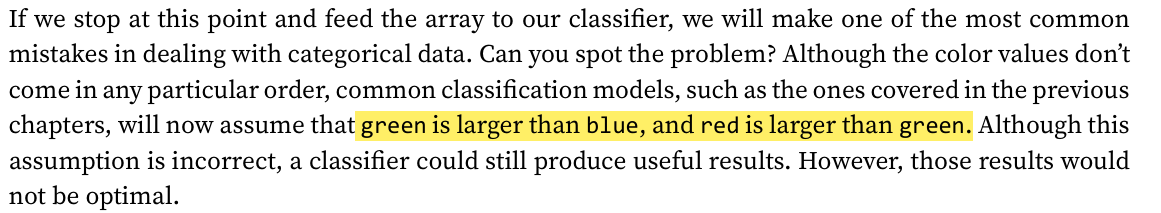

In [47]:
from sklearn.preprocessing import OneHotEncoder
X = df[['color', 'size', 'price']].values
color_ohe = OneHotEncoder()
color_ohe.fit_transform(X[:, 0].reshape(-1, 1)).toarray()

array([[0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.]])

In [48]:
from sklearn.compose import ColumnTransformer
X = df[['color', 'size', 'price']].values

c_transf = ColumnTransformer([
     ('onehot', OneHotEncoder(), [0]),
     ('nothing', 'passthrough', [1, 2])
 ])
c_transf.fit_transform(X).astype(float)


array([[ 0. ,  1. ,  0. ,  1. , 10.1],
       [ 0. ,  0. ,  1. ,  2. , 13.5],
       [ 1. ,  0. ,  0. ,  3. , 15.3]])

In [49]:
pd.get_dummies(df[['price', 'color', 'size']])

,price,size,color_blue,color_green,color_red
0,10.1,1,False,True,False
1,13.5,2,False,False,True
2,15.3,3,True,False,False


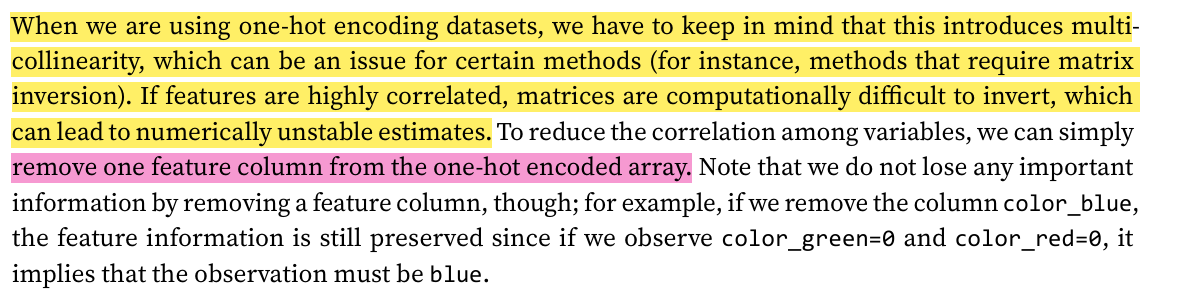

In [50]:
pd.get_dummies(df[['price', 'color', 'size']],
             drop_first=True)

,price,size,color_green,color_red
0,10.1,1,True,False
1,13.5,2,False,True
2,15.3,3,False,False


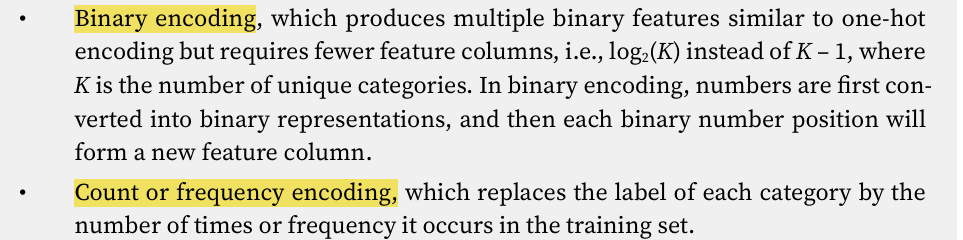

## Exploring The Wine dataset 

In [80]:
df_wine = pd.read_csv(
    'https://archive.ics.uci.edu/ml/'
    'machine-learning-databases/wine/wine.data',
    header=None
 )

In [81]:
df_wine.columns = ['Class label', 'Alcohol','Malic acid', 'Ash',
           'Alcalinity of ash', 'Magnesium',
                    'Total phenols', 'Flavanoids',
                     'Nonflavanoid phenols',
                    'Proanthocyanins',
                   'Color intensity', 'Hue',
                  'OD280/OD315 of diluted wines',
                  'Proline']

In [82]:
print('Class labels', np.unique(df_wine['Class label']))

Class labels [1 2 3]


In [57]:
df_wine.head()

,Class label,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [83]:

from sklearn.model_selection import train_test_split
X, y = df_wine.iloc[:,1:].values , df_wine.iloc[:,0].values

X_train , X_test , y_train , y_test = train_test_split(X,y , test_size = 0.3 , random_state = 0 , stratify=y)

###  Feature scaling 

- Decision trees do not necessarily need to worry about scalling 

- Most Machine Learning models need scaling 

- normalization and standardization

- normalization refers to the rescaling of the features to a range of [0, 1], which is a special case of min-max scaling.

In [86]:
from sklearn.preprocessing import MinMaxScaler
mms = MinMaxScaler()
X_train_norm = mms.fit_transform(X_train)
X_test_norm = mms.transform(X_test)

In [87]:
X_test_norm

array([[ 0.69005848,  0.22924901,  0.64052288,  0.30645161,  0.55555556,
         0.69655172,  0.51687764,  0.52      ,  0.39873418,  0.40497336,
         0.69148936,  0.60805861,  0.78245364],
       [ 0.22222222,  0.14031621,  0.54248366,  0.40860215,  0.41975309,
         0.3137931 ,  0.29746835,  0.64      ,  0.19303797,  0.10746004,
         1.03191489,  0.35164835,  0.05492154],
       [ 0.87134503,  0.22332016,  0.49019608,  0.17204301,  0.32098765,
         0.52413793,  0.45991561,  0.34      ,  0.49367089,  0.31172291,
         0.57446809,  0.84615385,  0.72182596],
       [ 0.52339181,  0.2055336 ,  0.2875817 , -0.01075269,  0.37037037,
         0.57586207,  0.51054852,  0.26      ,  0.2721519 ,  0.23445826,
         0.60638298,  0.78021978,  0.55064194],
       [ 0.28070175,  0.06521739,  0.26143791,  0.38172043,  0.22222222,
         0.87586207,  0.71940928,  0.22      ,  0.48417722,  0.24511545,
         0.59574468,  0.54945055,  0.2724679 ],
       [ 0.30409357,  0.452569

In [88]:
from sklearn.preprocessing import StandardScaler
stdsc = StandardScaler()
X_train_std = stdsc.fit_transform(X_train)
X_test_std = stdsc.transform(X_test)
X_test_std

array([[ 8.94437367e-01, -3.88117877e-01,  1.10073064e+00,
        -8.12017114e-01,  1.13201117e+00,  1.09807851e+00,
         7.12041017e-01,  1.81013423e-01,  6.62804643e-02,
         5.12859235e-01,  7.96297849e-01,  4.48295020e-01,
         1.90593792e+00],
       [-1.04879931e+00, -7.72993966e-01,  5.41190056e-01,
        -2.40938809e-01,  3.49414498e-01, -7.07219221e-01,
        -3.08121293e-01,  6.76138376e-01, -1.03520519e+00,
        -9.06567274e-01,  2.24570604e+00, -5.61881713e-01,
        -1.22874035e+00],
       [ 1.64744158e+00, -4.13776283e-01,  2.42768413e-01,
        -1.56343594e+00, -2.19746720e-01,  2.84881333e-01,
         4.47191186e-01, -5.61674005e-01,  5.74658458e-01,
         6.79643589e-02,  2.98063782e-01,  1.38631627e+00,
         1.64471473e+00],
       [ 2.02159300e-01, -4.90751501e-01, -9.13615453e-01,
        -2.58536553e+00,  6.48338887e-02,  5.28840485e-01,
         6.82613258e-01, -8.91757306e-01, -6.11556861e-01,
        -3.00662824e-01,  4.33945800e

### Selecting meaningful features

##### Some solutions ro Overfitting Includes 

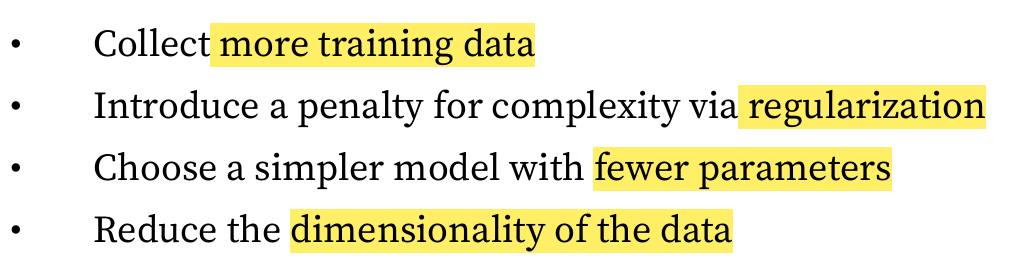

##### L1 and L2 regularization as penalties against model complexity

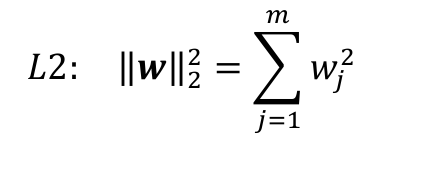     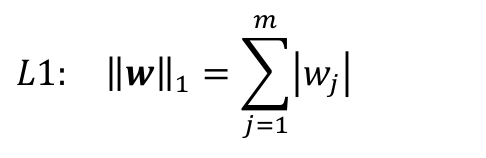

In [89]:
from sklearn.linear_model import LogisticRegression
LogisticRegression(penalty='l1',
                    solver='liblinear',
                    multi_class='ovr')

LogisticRegression(multi_class='ovr', penalty='l1', solver='liblinear')

In [90]:
lr = LogisticRegression(penalty='l1',
                         C=1.0,
                         solver='liblinear',
                          multi_class='ovr')
# Note that C=1.0 is the default. You can increase
  # or decrease it to make the regularization effect
# stronger or weaker, respectively.
lr.fit(X_train_std, y_train)
print('Training accuracy:', lr.score(X_train_std, y_train))

print('Test accuracy:', lr.score(X_test_std, y_test))


Training accuracy: 1.0
Test accuracy: 1.0


c:\Users\muham\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


In [ ]:
#  Since we fit the LogisticRegression object on a multiclass dataset via the one-versus-rest (OvR) 
# approach, the first intercept belongs to the model that fits class 1 versus classes 2 and 3, the second 
# value is the intercept of the model that fits class 2 versus classes 1 and 3, and the third value is the 
# intercept of the model that fits class 3 versus classes 1 and 2:
lr.intercept_

array([-1.26362123, -1.21611208, -2.37025093])

In [ ]:
# we could enforce sparsity (more zero entries) by further 
# increasing the regularization strength—that is, choosing lower values for the C parameter.
lr.coef_

array([[ 1.24564153,  0.18062556,  0.74511649, -1.16277852,  0.        ,
         0.        ,  1.16433648,  0.        ,  0.        ,  0.        ,
         0.        ,  0.55309981,  2.50968279],
       [-1.53668592, -0.38713593, -0.99541134,  0.36520113, -0.05954385,
         0.        ,  0.66828046,  0.        ,  0.        , -1.93457811,
         1.23331648,  0.        , -2.23114467],
       [ 0.13564255,  0.16833664,  0.35720241,  0.        ,  0.        ,
         0.        , -2.43833305,  0.        ,  0.        ,  1.56392984,
        -0.81906319, -0.49195714,  0.        ]])

c:\Users\muham\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\muham\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\muham\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\muham\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1256: FutureWarning: 'multi_clas

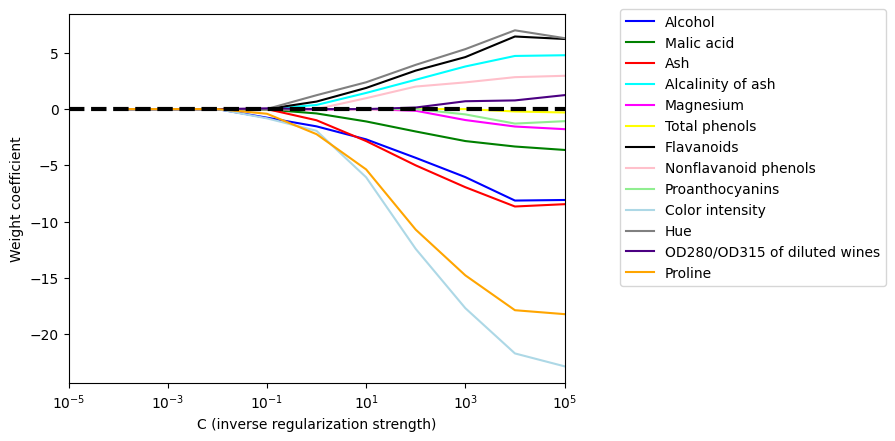

In [69]:
import matplotlib.pyplot as plt
fig = plt.figure()
ax = plt.subplot(111)
colors = ['blue', 'green', 'red', 'cyan',
            'magenta', 'yellow', 'black',
            'pink', 'lightgreen', 'lightblue',
            'gray', 'indigo', 'orange']
weights, params = [], []
for c in np.arange(-4., 6.):
      lr = LogisticRegression(penalty='l1', C=10.**c,
                              solver='liblinear',
                              multi_class='ovr', random_state=0)
      lr.fit(X_train_std, y_train)
      weights.append(lr.coef_[1])
      params.append(10**c)
                
weights = np.array(weights)
for column, color in zip(range(weights.shape[1]), colors):
     plt.plot(params, weights[:, column],
              label=df_wine.columns[column + 1],
              color=color)
plt.axhline(0, color='black', linestyle='--', linewidth=3)
plt.xlim([10**(-5), 10**5])
plt.ylabel('Weight coefficient')
plt.xlabel('C (inverse regularization strength)')
plt.xscale('log')
plt.legend(loc='upper left')
ax.legend(loc='upper center',
           bbox_to_anchor=(1.38, 1.03),
           ncol=1, fancybox=True)
plt.show()

### Sequential feature selection algorithms


- Sequential feature selection algorithms are a family of greedy search algorithms that are used to 
    reduce an initial d-dimensional feature space to a k-dimensional feature subspace where k < d
 
- sequential backward selection (SBS), which aims to 
    reduce the dimensionality of the initial feature subspace with a minimum decay in the performance 
        at each stage we eliminate the feature that causes the least performance loss after removal

- 

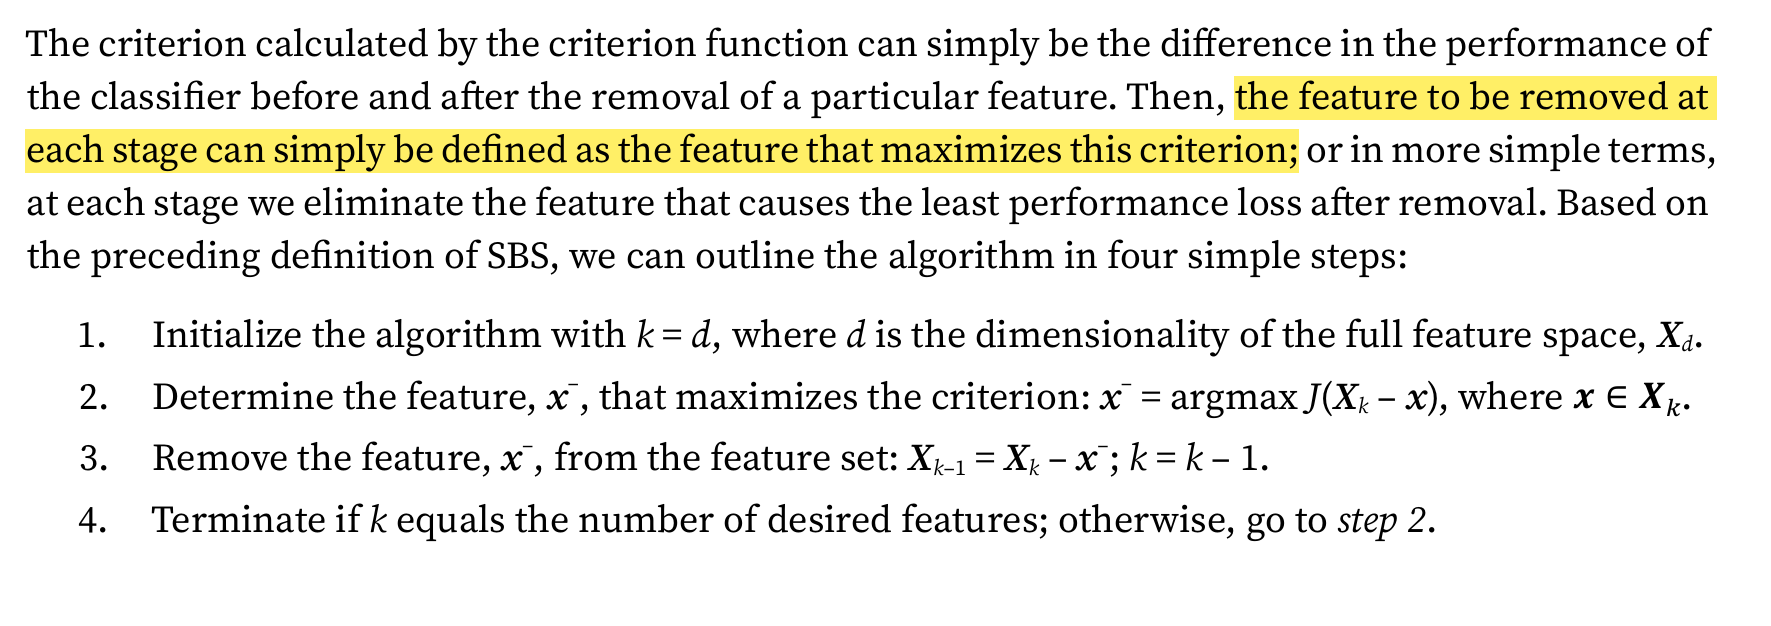

In [71]:
from sklearn.base import clone
from itertools import combinations
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

In [113]:
class SBS: 

    def __init__(self , estimator , k_features , scoring = accuracy_score , test_size = 0.25 , random_state = 1):

        self.scoring = scoring 
        self.estimator = clone(estimator) 
        self.k_features = k_features
        self.test_size = test_size
        self.random_state = random_state

    def fit(self , X , y): 

        X_train, X_test, y_train, y_test = \
            train_test_split(X, y, test_size=self.test_size,
                             random_state=self.random_state)
        
        dim = X_train.shape[1]
        self.indices_ = tuple(range(dim))
        self.subsets_ = [self.indices_]
        score = self._calc_score(X_train , y_train , X_test , y_test ,self.indices_)

        self.scores_ = [score]
        
        while dim > self.k_features:
            scores = []
            subsets = []
            for p in combinations(self.indices_, r=dim - 1):

                score = self._calc_score(X_train, y_train , X_test, y_test, p)
                scores.append(score)
                subsets.append(p)

            best = np.argmax(scores)
            self.indices_ = subsets[best]
            self.subsets_.append(self.indices_)
            dim -= 1

            self.scores_.append(scores[best])

        self.k_score_ = self.scores_[-1]

        return self 
        
    def transform(self , X): 
        return X[: , self.indices_]
    
    def _calc_score(self , X_train , y_train , X_test , y_test , indices): 
        self.estimator.fit(X_train[:,indices] , y_train)
        y_pred = self.estimator.predict(X_test[:,indices])
        score = self.scoring(y_test,y_pred)
        return score 




In [114]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
sbs = SBS(knn, k_features=1)
sbs.fit(X_train_std, y_train)

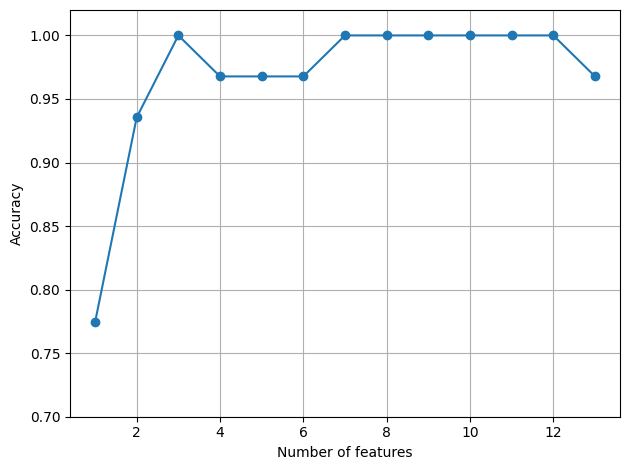

In [115]:
k_feat = [len(k) for k in sbs.subsets_]
plt.plot(k_feat, sbs.scores_, marker='o')
plt.ylim([0.7, 1.02])
plt.ylabel('Accuracy')
plt.xlabel('Number of features')
plt.grid()
plt.tight_layout()
plt.show()

In [116]:
k3 = list(sbs.subsets_[10])
print(df_wine.columns[1:][k3])

Index(['Alcohol', 'Malic acid', 'OD280/OD315 of diluted wines'], dtype='object')


In [117]:
knn.fit(X_train_std, y_train)

print('Training accuracy:', knn.score(X_train_std, y_train))

Training accuracy: 0.967741935483871


In [118]:
print('Test accuracy:', knn.score(X_test_std, y_test))


Test accuracy: 0.9629629629629629


In [119]:
# Uisng the three features that got the results we saw 

knn.fit(X_train_std[:, k3], y_train)

print('Training accuracy:', knn.score(X_train_std[:, k3], y_train))

print('Test accuracy:',knn.score(X_test_std[:, k3], y_test))


Training accuracy: 0.9516129032258065
Test accuracy: 0.9259259259259259


### Assessing feature importance with random forests

 1) Proline                        0.185453
 2) Flavanoids                     0.174751
 3) Color intensity                0.143920
 4) OD280/OD315 of diluted wines   0.136162
 5) Alcohol                        0.118529
 6) Hue                            0.058739
 7) Total phenols                  0.050872
 8) Magnesium                      0.031357
 9) Malic acid                     0.025648
10) Proanthocyanins                0.025570
11) Alcalinity of ash              0.022366
12) Nonflavanoid phenols           0.013354
13) Ash                            0.013279


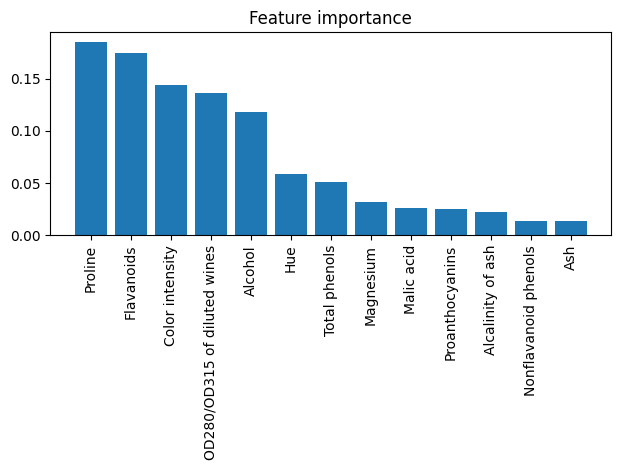

In [120]:
from sklearn.ensemble import RandomForestClassifier

feat_labels = df_wine.columns[1:]
forest = RandomForestClassifier(n_estimators=500,
                                  random_state=1)
forest.fit(X_train, y_train)
importances = forest.feature_importances_
indices = np.argsort(importances)[::-1]
for f in range(X_train.shape[1]):
     print("%2d) %-*s %f" % (f + 1, 30,
                              feat_labels[indices[f]],

                              importances[indices[f]]))
plt.title('Feature importance')
plt.bar(range(X_train.shape[1]),
         importances[indices],
         align='center')
plt.xticks(range(X_train.shape[1]),
             feat_labels[indices], rotation=90)
plt.xlim([-1, X_train.shape[1]])
plt.tight_layout()
plt.show()

In [128]:
from sklearn.feature_selection import SelectFromModel

sfm = SelectFromModel(forest, threshold = 0.1 ,  prefit=True)
X_selected = sfm.transform(X_train)
print('Number of features that meet this threshold',       
'criterion:', X_selected.shape[1])
#Number of features that meet this threshold criterion: 5
for f in range(X_selected.shape[1]):
   
    print("%2d) %-*s %f" % (f + 1, 30,
                        feat_labels[indices[f]],
                                importances[indices[f]]))

Number of features that meet this threshold criterion: 5
 1) Proline                        0.185453
 2) Flavanoids                     0.174751
 3) Color intensity                0.143920
 4) OD280/OD315 of diluted wines   0.136162
 5) Alcohol                        0.118529
